
# Finite-feature to continuum convergence for CFKS

This notebook verifies numerically, for the first-order oscillatory ODE,
\[
u'(x)=\cos(15x),\qquad x\in[-2\pi,2\pi],\qquad u(0)=0,
\]
that the finite Gaussian-RBF feature model converges to the bounded continuum-feature kernel formulation as the number of sampled centers \(M\) increases.

For each \(M\) and random realization, the notebook measures

\[
E_K=\frac{\|K_M-K_\rho\|_F}{\|K_\rho\|_F},
\qquad
E_G=\frac{\|G_M-G_\rho\|_F}{\|G_\rho\|_F},
\qquad
E_u=
\left(
\frac{1}{N_t}\sum_i |u_M(x_i)-u_{\rm CFKS}(x_i)|^2
\right)^{1/2}.
\]


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from scipy.linalg import solve
from time import perf_counter

from kapi_onet_publication_style import (
    SINGLE_COLUMN_WIDTH,
    DOUBLE_COLUMN_WIDTH,
    BLUE,
    ORANGE,
    GREEN,
    BLACK,
    GRAY,
    add_major_y_grid,
    save_figure,
)

rng_master = np.random.default_rng(12345)

XL, XR = -2*np.pi, 2*np.pi
omega = 15.0
sigma = 0.10
ca, cb = XL - 0.75, XR + 0.75

Np = 161
xP = np.linspace(XL, XR, Np)
xB = np.array([0.0])
xT = np.linspace(XL, XR, 2001)

rhs = np.r_[np.cos(omega*xP), 0.0]

M_list = np.array([25, 50, 100, 200, 500, 1000, 2000, 5000], dtype=int)
n_realizations = 20
ridge_rel = 1e-10



## Exact bounded Gaussian population kernel and derivatives


In [2]:

def _moments(mu, nmax):
    # J_n(mu) = integral_{ca}^{cb} (c-mu)^n exp(-(c-mu)^2/sigma^2) dc
    mu = np.asarray(mu, float)
    A = ca - mu
    B = cb - mu

    J = [None]*(nmax+1)
    J[0] = 0.5*np.sqrt(np.pi)*sigma*(erf(B/sigma) - erf(A/sigma))
    if nmax >= 1:
        J[1] = 0.5*sigma**2*(np.exp(-(A/sigma)**2) - np.exp(-(B/sigma)**2))

    for n in range(2, nmax+1):
        boundary = B**(n-1)*np.exp(-(B/sigma)**2) - A**(n-1)*np.exp(-(A/sigma)**2)
        J[n] = -0.5*sigma**2*boundary + 0.5*(n-1)*sigma**2*J[n-2]
    return J

def population_block(x, y, px=0, py=0):
    x = np.asarray(x, float)[:, None]
    y = np.asarray(y, float)[None, :]
    m = 0.5*(x+y)
    d = x-y

    pref = np.exp(-(d**2)/(4*sigma**2)) / (cb-ca)
    J = _moments(m, 2)

    if px == 0 and py == 0:
        poly = J[0]
    elif px == 1 and py == 0:
        poly = (J[1] - 0.5*d*J[0]) / sigma**2
    elif px == 0 and py == 1:
        poly = (J[1] + 0.5*d*J[0]) / sigma**2
    elif px == 1 and py == 1:
        poly = (J[2] - 0.25*d**2*J[0]) / sigma**4
    else:
        raise NotImplementedError("Only derivative orders 0 and 1 are used here.")
    return pref*poly

def k00(x, y): return population_block(x, y, 0, 0)
def k10(x, y): return population_block(x, y, 1, 0)
def k01(x, y): return population_block(x, y, 0, 1)
def k11(x, y): return population_block(x, y, 1, 1)


In [3]:

def k00_erf(x, y):
    x = np.asarray(x, float)[:, None]
    y = np.asarray(y, float)[None, :]
    m = 0.5*(x+y)
    d = x-y
    return (
        np.sqrt(np.pi)*sigma/(2*(cb-ca))
        * np.exp(-(d**2)/(4*sigma**2))
        * (erf((cb-m)/sigma) - erf((ca-m)/sigma))
    )

test = np.max(np.abs(k00(xP[:7], xP[:9]) - k00_erf(xP[:7], xP[:9])))
print(f"kernel closed-form consistency = {test:.3e}")


kernel closed-form consistency = 1.735e-18


## Exact CFKS reference system

In [4]:

Ginf = k11(xP, xP)
PBinf = k10(xP, xB)
BBinf = k00(xB, xB)

Kc_inf = np.block([
    [Ginf,    PBinf],
    [PBinf.T, BBinf]
])
Kc_inf = 0.5*(Kc_inf + Kc_inf.T)

lam_inf = ridge_rel*np.linalg.norm(Kc_inf, 2)
alpha_inf = solve(Kc_inf + lam_inf*np.eye(Kc_inf.shape[0]), rhs, assume_a="sym")

KT_P = k01(xT, xP)
KT_B = k00(xT, xB)
u_cfks = np.c_[KT_P, KT_B] @ alpha_inf

u_exact = np.sin(omega*xT)/omega
rmse_cfks_exact = np.sqrt(np.mean((u_cfks-u_exact)**2))
print(f"CFKS RMSE vs exact solution = {rmse_cfks_exact:.6e}")


CFKS RMSE vs exact solution = 1.541214e-05


## Finite-feature convergence experiment

In [5]:

Kval_inf = k00(xP, xP)

EK = np.zeros((len(M_list), n_realizations))
EG = np.zeros_like(EK)
EU = np.zeros_like(EK)
EX = np.zeros_like(EK)
times = np.zeros_like(EK)

for iM, M in enumerate(M_list):
    for r in range(n_realizations):
        rng = np.random.default_rng(rng_master.integers(0, 2**63-1))
        c = rng.uniform(ca, cb, size=M)

        t0 = perf_counter()

        PhiP = np.exp(-((xP[:, None]-c[None, :])**2)/(2*sigma**2))
        DPhiP = -(xP[:, None]-c[None, :])/sigma**2 * PhiP
        PhiB = np.exp(-((xB[:, None]-c[None, :])**2)/(2*sigma**2))

        Kval_M = (PhiP @ PhiP.T)/M
        G_M = (DPhiP @ DPhiP.T)/M

        Z = np.vstack([DPhiP, PhiB]) / np.sqrt(M)
        Kc_M = Z @ Z.T
        lam_M = ridge_rel*np.linalg.norm(Kc_M, 2)
        alpha_M = solve(Kc_M + lam_M*np.eye(Kc_M.shape[0]), rhs, assume_a="sym")

        PhiT = np.exp(-((xT[:, None]-c[None, :])**2)/(2*sigma**2))
        KT_P_M = (PhiT @ DPhiP.T)/M
        KT_B_M = (PhiT @ PhiB.T)/M
        u_M = np.c_[KT_P_M, KT_B_M] @ alpha_M

        times[iM, r] = perf_counter() - t0

        EK[iM, r] = np.linalg.norm(Kval_M-Kval_inf, "fro") / np.linalg.norm(Kval_inf, "fro")
        EG[iM, r] = np.linalg.norm(G_M-Ginf, "fro") / np.linalg.norm(Ginf, "fro")
        EU[iM, r] = np.sqrt(np.mean((u_M-u_cfks)**2))
        EX[iM, r] = np.sqrt(np.mean((u_M-u_exact)**2))

    print(
        f"M={M:5d} | "
        f"E_K={EK[iM].mean():.3e} | "
        f"E_G={EG[iM].mean():.3e} | "
        f"E_u={EU[iM].mean():.3e}"
    )


M=   25 | E_K=1.521e+00 | E_G=1.738e+00 | E_u=5.807e-02
M=   50 | E_K=1.057e+00 | E_G=1.214e+00 | E_u=6.144e-02
M=  100 | E_K=7.246e-01 | E_G=8.445e-01 | E_u=6.580e-02
M=  200 | E_K=5.297e-01 | E_G=6.105e-01 | E_u=5.928e-02
M=  500 | E_K=3.170e-01 | E_G=3.700e-01 | E_u=5.976e-05
M= 1000 | E_K=2.396e-01 | E_G=2.752e-01 | E_u=1.731e-05
M= 2000 | E_K=1.649e-01 | E_G=1.914e-01 | E_u=9.043e-06
M= 5000 | E_K=1.037e-01 | E_G=1.179e-01 | E_u=4.451e-06


In [6]:

print("\nM        K error (mean±sd)      Operator error (mean±sd)    u_M-CFKS RMSE (mean±sd)")
for i, M in enumerate(M_list):
    print(
        f"{M:5d}   "
        f"{EK[i].mean():.3e} ± {EK[i].std(ddof=1):.2e}    "
        f"{EG[i].mean():.3e} ± {EG[i].std(ddof=1):.2e}    "
        f"{EU[i].mean():.3e} ± {EU[i].std(ddof=1):.2e}"
    )



M        K error (mean±sd)      Operator error (mean±sd)    u_M-CFKS RMSE (mean±sd)
   25   1.521e+00 ± 1.96e-01    1.738e+00 ± 1.55e-01    5.807e-02 ± 4.47e-03
   50   1.057e+00 ± 9.98e-02    1.214e+00 ± 9.23e-02    6.144e-02 ± 4.91e-03
  100   7.246e-01 ± 5.93e-02    8.445e-01 ± 5.23e-02    6.580e-02 ± 1.29e-02
  200   5.297e-01 ± 5.90e-02    6.105e-01 ± 5.31e-02    5.928e-02 ± 3.38e-02
  500   3.170e-01 ± 2.50e-02    3.700e-01 ± 2.38e-02    5.976e-05 ± 3.69e-05
 1000   2.396e-01 ± 1.50e-02    2.752e-01 ± 1.43e-02    1.731e-05 ± 8.67e-06
 2000   1.649e-01 ± 1.55e-02    1.914e-01 ± 1.34e-02    9.043e-06 ± 3.06e-06
 5000   1.037e-01 ± 9.22e-03    1.179e-01 ± 8.87e-03    4.451e-06 ± 1.54e-06


## Convergence plots

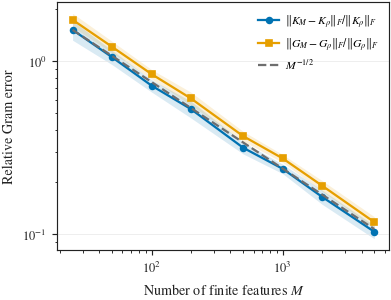

In [7]:

def mean_sd(A):
    return A.mean(axis=1), A.std(axis=1, ddof=1)

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.78*SINGLE_COLUMN_WIDTH))

for A, label, color, marker in [
    (EK, r"$\|K_M-K_\rho\|_F/\|K_\rho\|_F$", BLUE, "o"),
    (EG, r"$\|G_M-G_\rho\|_F/\|G_\rho\|_F$", ORANGE, "s"),
]:
    mu, sd = mean_sd(A)
    ax.loglog(M_list, mu, marker=marker, color=color, label=label)
    ax.fill_between(
        M_list,
        np.maximum(mu-sd, 1e-16),
        mu+sd,
        color=color,
        alpha=0.15,
        linewidth=0,
    )

guide = EK.mean(axis=1)[0] * np.sqrt(M_list[0]/M_list)
ax.loglog(M_list, guide, "--", color=GRAY, label=r"$M^{-1/2}$")

ax.set_xlabel(r"Number of finite features $M$")
ax.set_ylabel("Relative Gram error")
add_major_y_grid(ax)
ax.legend()
fig.tight_layout()

save_figure(fig, "CFKS_finite_feature_gram_convergence")
plt.show()


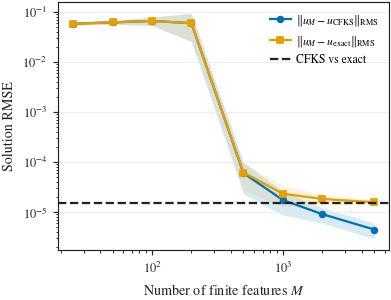

In [8]:

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.78*SINGLE_COLUMN_WIDTH))

mu, sd = mean_sd(EU)
ax.loglog(
    M_list, mu, "o-",
    color=BLUE,
    label=r"$\|u_M-u_{\rm CFKS}\|_{\rm RMS}$",
)
ax.fill_between(
    M_list,
    np.maximum(mu-sd, 1e-16),
    mu+sd,
    color=BLUE,
    alpha=0.15,
    linewidth=0,
)

mu_ex, sd_ex = mean_sd(EX)
ax.loglog(
    M_list, mu_ex, "s-",
    color=ORANGE,
    label=r"$\|u_M-u_{\rm exact}\|_{\rm RMS}$",
)
ax.fill_between(
    M_list,
    np.maximum(mu_ex-sd_ex, 1e-16),
    mu_ex+sd_ex,
    color=ORANGE,
    alpha=0.12,
    linewidth=0,
)

ax.axhline(
    rmse_cfks_exact,
    linestyle="--",
    color=BLACK,
    label="CFKS vs exact",
)

ax.set_xlabel(r"Number of finite features $M$")
ax.set_ylabel("Solution RMSE")
add_major_y_grid(ax)
ax.legend()
fig.tight_layout()

save_figure(fig, "CFKS_finite_feature_solution_convergence")
plt.show()


## Bounded population kernel versus full-line Gaussian limit

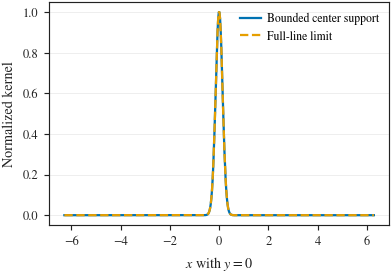

In [9]:

xcmp = np.linspace(XL, XR, 500)
y0 = np.array([0.0])

kb = k00(xcmp, y0).ravel()
kfull = np.sqrt(np.pi)*sigma*np.exp(-(xcmp-y0[0])**2/(4*sigma**2))
kb_integral_measure = (cb-ca)*kb

kb_n = kb_integral_measure / np.max(kb_integral_measure)
kf_n = kfull / np.max(kfull)

fig, ax = plt.subplots(figsize=(SINGLE_COLUMN_WIDTH, 0.72*SINGLE_COLUMN_WIDTH))
ax.plot(xcmp, kb_n, color=BLUE, label="Bounded center support")
ax.plot(xcmp, kf_n, "--", color=ORANGE, label="Full-line limit")
ax.set_xlabel(r"$x$ with $y=0$")
ax.set_ylabel("Normalized kernel")
add_major_y_grid(ax)
ax.legend()
fig.tight_layout()

save_figure(fig, "CFKS_bounded_vs_full_line_kernel")
plt.show()


In [10]:

np.savez_compressed(
    "CFKS_finite_feature_convergence_results.npz",
    M_list=M_list,
    n_realizations=n_realizations,
    EK=EK, EG=EG, EU=EU, EX=EX, times=times,
    xP=xP, xT=xT, u_cfks=u_cfks, u_exact=u_exact,
    sigma=sigma, ca=ca, cb=cb, omega=omega,
    rmse_cfks_exact=rmse_cfks_exact,
)
print("Saved CFKS_finite_feature_convergence_results.npz")


Saved CFKS_finite_feature_convergence_results.npz
